# MODULE 45 — FACE DETECTION, LANDMARKS & ALIGNMENT

# 45.3 FACE ALIGNMENT

**Priority:** Must Know  
**Domain:** Computer Vision

Face alignment is the process of transforming a detected face into a standardized position, orientation, and scale using facial landmarks.

The main goal is simple:

**Make faces look geometrically consistent before passing them into a face recognition model.**

---

## 1. Why Do We Need Face Alignment?

Imagine a face recognition model trained using images where:

- Both eyes are at approximately the same height.
- The face is positioned near the centre.
- The face has a consistent size.
- The head is approximately upright.

Now consider a new image where the person is:

- Tilting their head.
- Looking slightly sideways.
- Positioned toward the edge of the image.
- Very close to or far from the camera.

Even though it is the same person, the face occupies a different geometric arrangement.

This creates unnecessary variation for the recognition model.

Face alignment reduces this geometric variation, allowing the recognition model to focus more on identity-related facial features rather than differences in image positioning.

### Understanding the Problem

Consider two images of the same person:

**Image A:**

- Face is upright.
- Eyes are horizontally aligned.
- Face is centred.
- Face occupies a consistent area.

**Image B:**

- Face is tilted.
- Eyes are at different vertical positions.
- Face is shifted.
- Face has a different scale.

A recognition model may encounter difficulty because the facial features appear at different spatial locations.

Face alignment attempts to standardize these geometric differences.

### Why Is This Important?

Deep learning models learn patterns from their training data.

If the training images contain consistently aligned faces, providing similarly aligned images during inference helps maintain consistency between training and testing conditions.

---

## 2. Face Alignment Pipeline

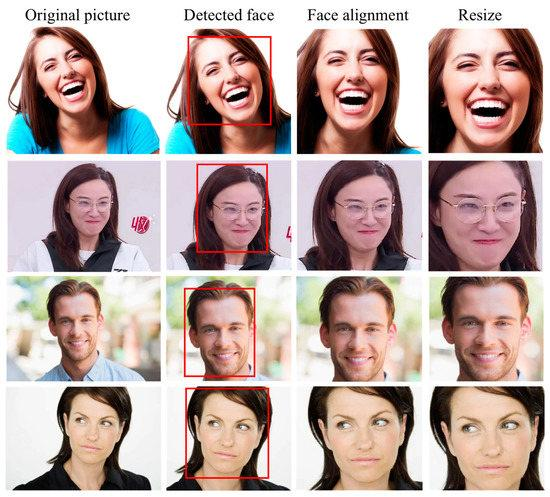


Your syllabus pipeline is correct:

```text
Detected Face
      ↓
Facial Landmarks
      ↓
Geometric Alignment
      ↓
Normalized Face
      ↓
Face Recognition
```

Let's understand each stage.

### Stage 1 — Detected Face

The face detector identifies the face and returns a bounding box.

Example:

```python
bbox = (50, 40, 250, 240)
```

This tells us where the face is located in the image.

### Stage 2 — Facial Landmarks

A landmark detection model identifies important facial points.

For example:

```python
Left eye  = (100, 100)
Right eye = (180, 120)
Nose tip  = (140, 160)
```

Notice that the eyes are not at the same vertical position. This indicates that the face is tilted relative to the image's horizontal axis.


### Stage 3 — Geometric Alignment

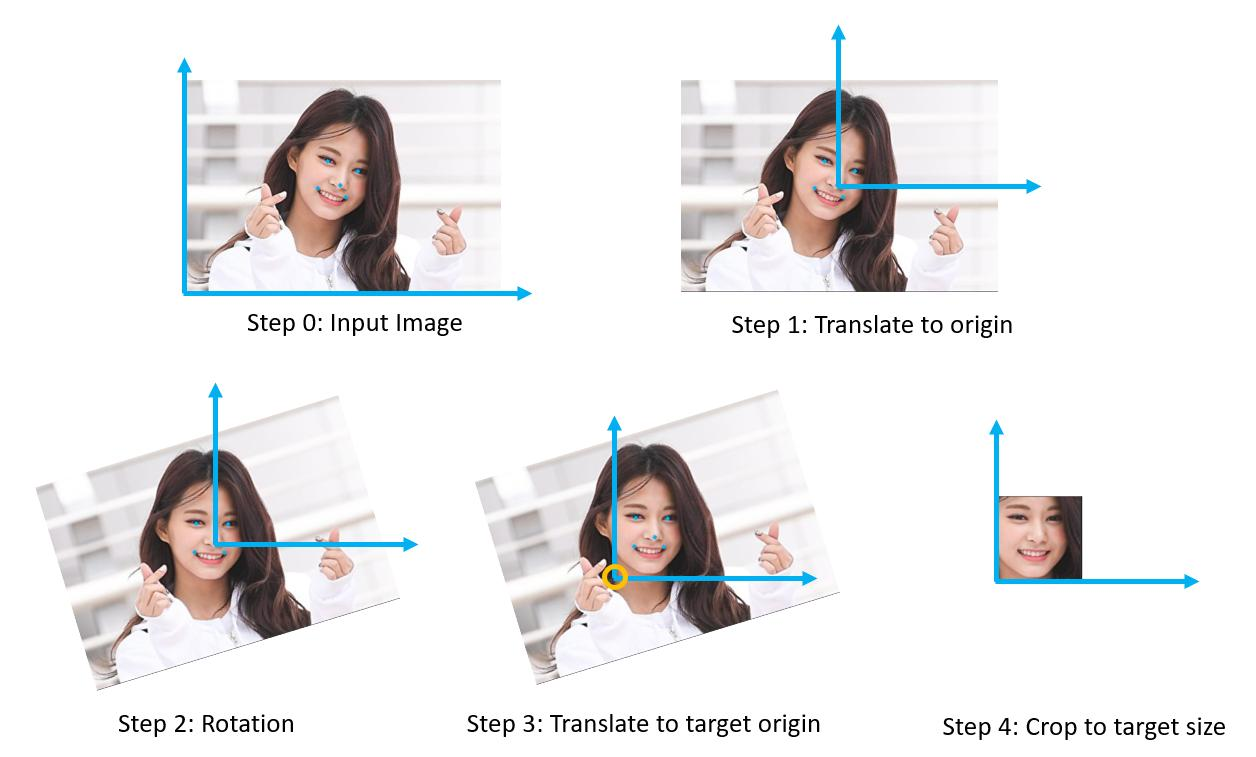

We calculate a transformation using the detected landmarks.

The transformation corrects:

1. **Rotation** — makes the eyes approximately horizontal.
2. **Scaling** — adjusts the face to a standard size.
3. **Translation** — moves the face to a standard position.

### Stage 4 — Normalized Face

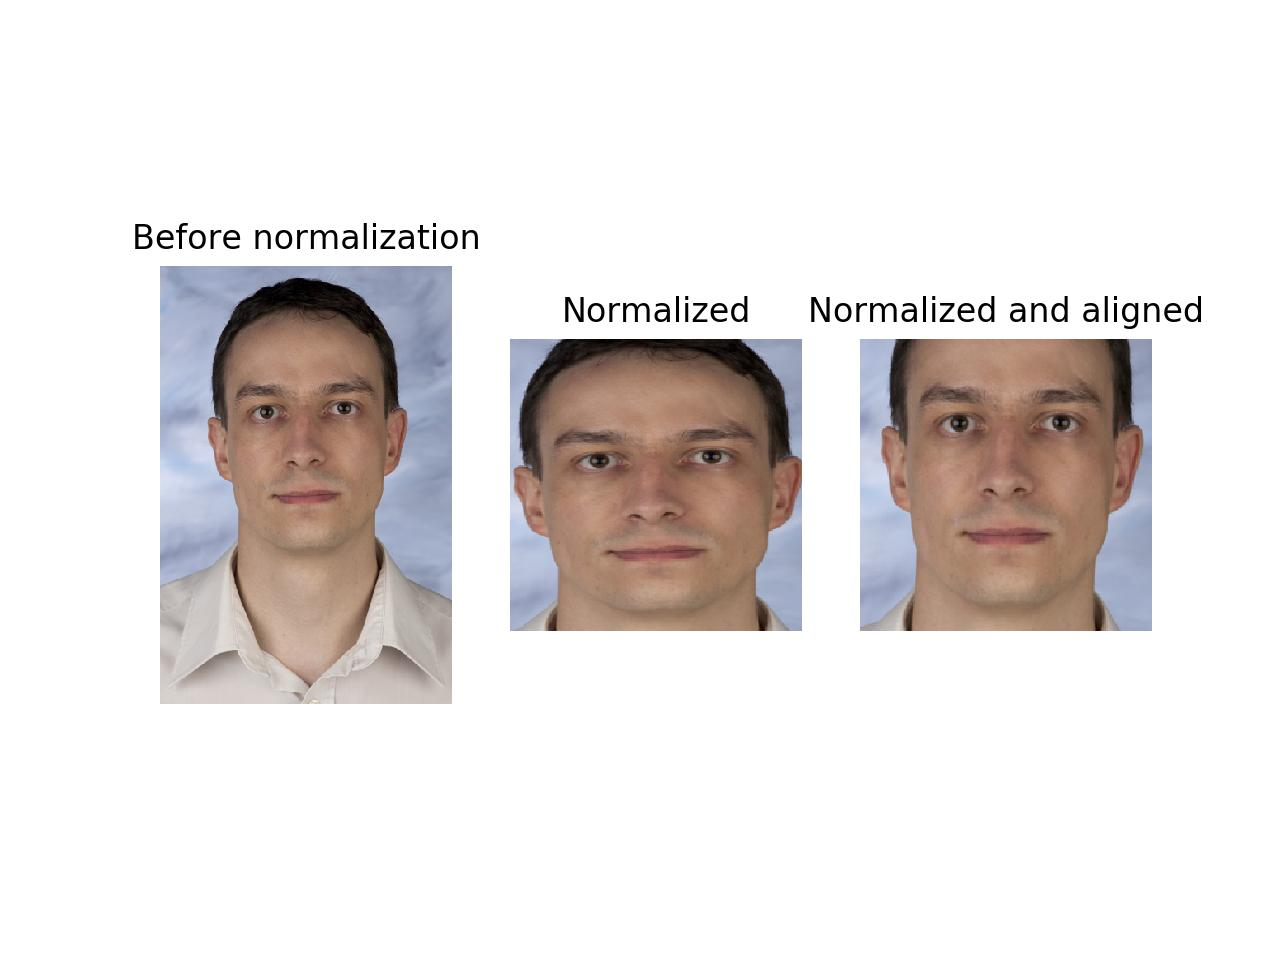

After applying the transformation, the face is cropped into a standardized output size.

For example:

| Parameter | Dimensions |
|---|---|
| Original face | 200 × 200 pixels |
| Aligned face | 112 × 112 pixels |

The output dimensions depend on the recognition model's input requirements.

### Stage 5 — Face Recognition

The normalized face is passed into a pretrained face recognition model.

The model extracts a feature representation called an **embedding**.

Two face embeddings can then be compared using cosine similarity or Euclidean distance.

### Important Distinction

| Task | Main Question |
|---|---|
| Face detection | Where is the face? |
| Landmark detection | Where are the facial reference points? |
| Face alignment | How can we standardize its geometry? |
| Face recognition | Does this face match another face? |

---

## 3. What Happens Mathematically?

Face alignment generally uses a geometric transformation to map the detected facial landmarks to predefined target positions.

### A. Rotation Correction

Suppose the two eye landmarks are:

$$
L=(100,100),\qquad R=(180,120)
$$

The right eye is 20 pixels lower than the left eye.

We calculate the angle between the eyes:

$$
\theta=\tan^{-1}\left(\frac{y_R-y_L}{x_R-x_L}\right)
$$

Substituting the values:

$$
\theta=\tan^{-1}\left(\frac{20}{80}\right)
$$

$$
\boxed{\theta\approx14.04^\circ}
$$

The face is tilted by approximately 14 degrees relative to the horizontal.

Alignment rotates the face in the opposite direction to make the eyes approximately horizontal.

### B. Scaling

After rotation, the distance between the eyes might still differ from the expected distance.

Suppose:

- Original eye distance = 80 pixels.
- Desired eye distance = 40 pixels.

The scaling factor is:

$$
s=\frac{\text{Desired eye distance}}{\text{Original eye distance}}
$$

$$
s=\frac{40}{80}
$$

$$
\boxed{s=0.5}
$$

The face is scaled down by a factor of 0.5.

### C. Translation

Finally, the face is moved to a standard position.

For example, the aligned face may have its eye midpoint positioned at a predefined coordinate in the output image.

This ensures that faces are consistently positioned.

---

## 4. Affine and Similarity Transformations

This is an important mathematical concept behind face alignment.

### A. General 2D Affine Transformation

A general 2D affine transformation can be represented as:

$$
\begin{bmatrix}
x'\\
y'
\end{bmatrix}
=
\begin{bmatrix}
a & b\\
c & d
\end{bmatrix}
\begin{bmatrix}
x\\
y
\end{bmatrix}
+
\begin{bmatrix}
t_x\\
t_y
\end{bmatrix}
$$

Where:

- \\(x,y\\): Original landmark coordinates.
- \\(x',y'\\): Transformed coordinates.
- \\(a,b,c,d\\): Transformation parameters.
- \\(t_x,t_y\\): Translation parameters.

An affine transformation can represent:

- Rotation.
- Scaling.
- Translation.
- Shear.

### B. Similarity Transformation

Similarity transformation is a more constrained form commonly used for face alignment.

It supports:

- Rotation.
- Uniform scaling.
- Translation.

It preserves angles and relative shape, making it suitable for standardizing face geometry without unnecessarily distorting facial proportions.

A 2D similarity transformation can be represented as:

$$
\begin{bmatrix}
x'\\
y'
\end{bmatrix}
=
\begin{bmatrix}
s\cos\theta & -s\sin\theta\\
s\sin\theta & s\cos\theta
\end{bmatrix}
\begin{bmatrix}
x\\
y
\end{bmatrix}
+
\begin{bmatrix}
t_x\\
t_y
\end{bmatrix}
$$

Where:

- \\(s\\): Uniform scaling factor.
- \\(\theta\\): Rotation angle.
- \\(t_x,t_y\\): Translation parameters.

### Similarity vs General Affine Transformation

| Property | Similarity Transformation | General Affine Transformation |
|---|---|---|
| Rotation | Yes | Yes |
| Uniform scaling | Yes | Yes |
| Translation | Yes | Yes |
| Non-uniform scaling | No | Yes |
| Shearing | No | Yes |
| Preserves angles | Yes | Not necessarily |
| Typical use | Face alignment | General geometric image transformations |

**Important:** Similarity transformation is generally preferred when the goal is to standardize face geometry without introducing unnecessary deformation.

---

## 5. Practical Implementation Using OpenCV

Let's understand how a real alignment operation works.

We will use five facial landmarks:

1. Left eye.
2. Right eye.
3. Nose tip.
4. Left mouth corner.
5. Right mouth corner.

The target landmarks represent the desired standardized face layout.

### Python Implementation

```python
import cv2
import numpy as np

# Example detected facial landmarks
source_points = np.array([
    [100, 100],  # Left eye
    [180, 120],  # Right eye
    [140, 160],  # Nose
    [110, 200],  # Left mouth
    [170, 200]   # Right mouth
], dtype=np.float32)

# Desired landmark positions in the aligned image
target_points = np.array([
    [38, 42],
    [74, 42],
    [56, 65],
    [42, 88],
    [70, 88]
], dtype=np.float32)

# Estimate similarity transformation
matrix, inliers = cv2.estimateAffinePartial2D(
    source_points,
    target_points
)

# Apply transformation to original face image
aligned_face = cv2.warpAffine(
    face_image,
    matrix,
    (112, 112)
)
```

### What Is Happening Here?

**1. `source_points`**

Actual landmark positions detected in the input face.

**2. `target_points`**

Standard positions where we want those landmarks.

**3. `cv2.estimateAffinePartial2D()`**

Estimates a similarity transformation between the source and target points.

**4. `cv2.warpAffine()`**

Applies that transformation to the image.

**5. `(112, 112)`**

Output image dimensions.

### Important Implementation Note

`face_image` must contain the original image or face crop in the coordinate system used by `source_points`.

The example assumes the landmarks are expressed in that same coordinate system.

This is an illustrative example. In a real implementation, use landmarks predicted by a face-landmark detector and check that transformation estimation succeeded before applying it.

For example:

```python
if matrix is not None:
    aligned_face = cv2.warpAffine(
        face_image,
        matrix,
        (112, 112)
    )
else:
    print("Transformation estimation failed.")
```

---

## 6. Why Does Alignment Improve Face Recognition?

Consider two images of the same person.

### Before Alignment

- Eyes tilted.
- Face position varies.
- Face scale varies.
- Facial features appear at different coordinates.

### After Alignment

- Face geometry is standardized.
- Eye positions are more consistent.
- Face occupies a consistent region.
- Facial features are positioned more consistently.

Without alignment, the recognition model may encounter unnecessary variations caused by:

- Head rotation.
- Different face positions.
- Different face sizes.
- Inconsistent eye and mouth positions.

With alignment, the model receives more geometrically consistent input.

This can improve recognition consistency, particularly when the recognition model was trained using aligned face crops.

### Important Limitation

Alignment cannot completely correct:

- Extreme head rotation.
- Occlusion.
- Poor lighting.
- Inaccurate landmarks.

It also does not guarantee improved recognition in every model or situation.

---

## 7. Industry Applications

| Application | Role of Face Alignment |
|---|---|
| Face authentication | Standardizes faces before embedding extraction |
| Smartphone face unlock | Helps prepare facial input for recognition |
| CCTV analytics | Preprocesses detected faces |
| Attendance systems | Makes face crops more consistent |
| Facial expression analysis | Standardizes facial geometry before analysis |

---

## 8. What You Should Remember

1. Face alignment standardizes facial position, orientation and scale.
2. Facial landmarks provide the reference coordinates for alignment.
3. Rotation correction makes the eyes approximately horizontal.
4. Scaling adjusts the face to the desired size.
5. Translation moves the face to a standard position.
6. Similarity transformation is commonly used to align faces while preserving proportions.
7. Alignment is preprocessing; it is not face recognition itself.

---

## 9. Must Know vs Good to Know

| Concept | Priority |
|---|---|
| Purpose of face alignment | Must Know |
| Rotation, scaling and translation | Must Know |
| Facial landmark-based alignment | Must Know |
| Similarity transformation | Must Know |
| Affine transformation mathematics | Good to Know |
| OpenCV alignment implementation | Good to Know |

---

## Technical Clarifications & Additional Engineering Notes

### 1. Coordinate Systems Must Match

When calculating the transformation, source landmarks must correspond to the image being transformed.

For example:

- If landmarks are detected on the original image, transform the original image.
- If landmarks are detected on a cropped face, transform that same cropped face.

Otherwise, the alignment transformation may produce incorrect results.

### 2. Transformation Estimation Can Fail

OpenCV's `estimateAffinePartial2D()` returns a transformation matrix and an inlier mask.

The transformation matrix can be `None` if estimation fails.

Always validate the output before calling `cv2.warpAffine()`.

### 3. Five-Point Face Alignment

Five-point alignment is widely used in face recognition preprocessing.

The five points generally correspond to:

1. Left eye.
2. Right eye.
3. Nose tip.
4. Left mouth corner.
5. Right mouth corner.

These reference points provide enough geometric information to estimate a similarity transformation.

### 4. Alignment Does Not Mean 3D Pose Correction

A 2D similarity transformation corrects image-plane rotation, scale and translation.

It does not fully undo perspective effects or reconstruct a face viewed from an extreme side angle.

For substantial head rotations, more advanced 3D methods may be required.

---